In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("Library imported successfully!")


Library imported successfully!


In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dataset Loaded Successfully!")
print("Shape of dataset:",df.shape)
print(df.head())

Dataset Loaded Successfully!
Shape of dataset: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  Te

In [7]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe(include="all"))

print("\nColumns Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nChurn Distribution:")
if "Churn" in df.columns:
    print(df["Churn"].value_counts(dropna=False))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [11]:
# Convert TotalCharges into numeric data
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("TotalCharges converted successfully!")

print(df["TotalCharges"].dtype)
print(df["TotalCharges"].head())

TotalCharges converted successfully!
float64
0      29.85
1    1889.50
2     108.15
3    1840.75
4     151.65
Name: TotalCharges, dtype: float64


In [12]:
before = len(df)
df=df.drop_duplicates().copy()
after=len(df)

print("Duplicate records removed:",before-after)
print("Dataset shape after removing duplicates:",df.shape)

Duplicate records removed: 0
Dataset shape after removing duplicates: (7043, 21)


In [13]:
for col in df.select_dtypes(
    include=["object","category","string"]
).columns:
    df[col]=df[col].str.strip()

for col in df.select_dtypes(
    include=["object","category","string"]
).columns:
    normalized=df[col].str.lower()
    df.loc[normalized =="yes",col]="Yes"
    df.loc[normalized == "no",col]="No"

if "gender" in df.columns:
    df["gender"]=df["gender"].str.lower().str.capitalize()

print("Inconsistent formatting standardized")
print(df.head())

Inconsistent formatting standardized
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV

In [17]:
for col in ["tenure","MonthlyCharges","TotalCharges"]:
    if col in df.columns:
        df[col]=pd.to_numeric(df[col], errors="coerce")

if "SeniorCitizen" in df.columns:
    df["SeniorCitizen"] = pd.to_numeric(
        df["SeniorCitizen"], errors="coerce"
    )
    df["SeniorCitizen"]=df["SeniorCitizen"].fillna(
    df["SeniorCitizen"].median()
    ).astype(int)

print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [19]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

exclude_cols = ["seniorCitizen","Churn"]
numeric_cols=[
    col for col in numeric_cols
    if col not in exclude_cols
    and col.lower() not in ["customerid","customer_id"]

]

outlier_counts={}

for col in numeric_cols:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1

    lower = Q1-1.5*IQR
    upper = Q3+1.5*IQR

    outlier_counts[col] = (
      (df[col]<lower) | (df[col]>upper)
    ).sum()

    df[col]=df[col].clip(lower=lower,upper=upper)

print("Outlier detected before capping")
print(pd.Series(outlier_counts))

Outlier detected before capping
SeniorCitizen     0
tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64


In [22]:
df["AverageMonthlySpend"] = (
    df["TotalCharges"] / df["tenure"].replace(0, np.nan)
).fillna(0)

print(df[["TotalCharges", "tenure", "AverageMonthlySpend"]].head())

   TotalCharges  tenure  AverageMonthlySpend
0         29.85       1            29.850000
1       1889.50      34            55.573529
2        108.15       2            54.075000
3       1840.75      45            40.905556
4        151.65       2            75.825000


In [23]:
 # Normalize column names for reliable identification
df.columns = df.columns.str.strip()

target = next(
    (col for col in df.columns if col.lower() == "churn"),
    None
)

if target is None:
    raise ValueError("Target column 'Churn' was not found.")

# Remove rows with missing target labels
df = df.dropna(subset=[target]).copy()

# Separate features and target
y = df[target].copy()

# Exclude customer ID from predictive features
id_cols = [
    col for col in df.columns
    if col.lower() in ["customerid", "customer_id"]
]

X = df.drop(columns=[target] + id_cols)

# Remove any columns that contain only one value
constant_cols = [
    col for col in X.columns if X[col].nunique(dropna=False) <= 1
]
X = X.drop(columns=constant_cols)

# Stratify only when each class has enough examples
stratify_arg = y if y.value_counts().min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=stratify_arg
)

# Separate numerical and categorical features
num_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

cat_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Preprocessing pipelines
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_features),
    ("cat", categorical_transformer, cat_features)
])

# Fit on training data; transform test data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training set:", X_train_processed.shape)
print("Testing set:", X_test_processed.shape)
print("Data split and preprocessing completed!")

Training set: (5634, 45)
Testing set: (1409, 45)
Data split and preprocessing completed!


In [24]:
df.to_csv("Telecom_Customer_Churn_Cleaned.csv", index=False)

# Save the split datasets for future modeling
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)

y_train.to_frame(name=target).to_csv(
    "y_train.csv", index=False
)
y_test.to_frame(name=target).to_csv(
    "y_test.csv", index=False
)

print("Cleaned dataset exported successfully!")
print("File: Telecom_Customer_Churn_Cleaned.csv")
print("Training and testing files saved successfully!")

Cleaned dataset exported successfully!
File: Telecom_Customer_Churn_Cleaned.csv
Training and testing files saved successfully!


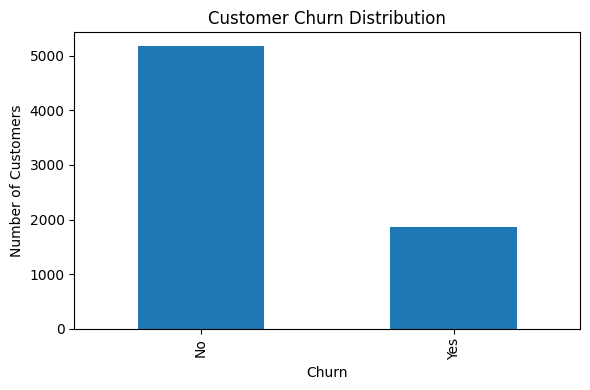

In [25]:
df[target].value_counts().plot(
    kind="bar",
    figsize=(6, 4),
    title="Customer Churn Distribution"
)

plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()